# Lattice construction

In [25]:
lattice_name   = 'v02_03_01_01'
description    = 'LGB lattice starting from v01_03_01_01 with separate tuning of outer reverse bends and higher MCF.'
finalized_date = '261116'

In [26]:
# Standard imports
import numpy as np
import scipy
import matplotlib.pyplot as plt

import pickle
import os
from copy import deepcopy

import at

import utils as u

from importlib import reload

reload(u.at);
reload(u.plot);

## Load ring

In [ ]:
with open('candidates/v01_03_01_01/ring.pkl', 'rb') as file:
    ring0 = pickle.load(file)

TDR_1 = u.at.TDR_1

## Decouple outer reverse bends

In [10]:
ring = deepcopy(ring0)

# Rename all to _v2
for e in ring:
    e.FamName = e.FamName.replace('_v1', '_v2')

# Rename all to R2
for e in ring['R1_v2']:
    e.FamName = 'R2_v2'

# Create deep copies from outermost to innermost slice
R1 = deepcopy(ring['R2_v2'][0])
R1.FamName = 'R1_v2'

ring[ring.uint32_refpts('R2_v2')[ 0]] = R1
ring[ring.uint32_refpts('R2_v2')[-1]] = R1

## Free-form optimization

In [5]:
def set_x(ring, x, index_rho, index_K):
    # Unpack
    L = x[0]
    rho_inv = x[1:len(index_rho)+1]
    K = x[len(index_rho)+1:]

    assert len(rho_inv) == len(index_rho), f"rho_inv and index_rho should have the same lengths but have lengths {len(rho_inv)} and {len(index_rho)}"
    assert len(K) == len(index_K), f"rho_inv and index_rho should have the same lengths but have lengths {len(K)} and {len(index_K)}"

    for e in ring['strx203']: e.Length = L
    for i, e in enumerate(ring[index_rho]): e.BendingAngle = e.Length * rho_inv[i]
    for i, e in enumerate(ring[index_K]): e.K = K[i]

def get_x(ring, index_rho, index_K):
    L = ring['strx203'][0].Length

    rho_inv = [ring[i].BendingAngle/ring[i].Length for i in index_rho]
    K       = [ring[i].K                           for i in index_K]

    return np.array([L] + rho_inv + K)

def loss(x, ring, index_rho, index_K):
    # Set fields
    set_x(ring, x, index_rho, index_K)

    try:
        emittance = 1e12 * ring.radiation_parameters().emittances[0]
    except Exception as e:
        emittance = 1000

    return emittance

def exact_constraints(x, ring, index_rho, index_K):
    # Set fields
    set_x(ring, x, index_rho, index_K)

    """ Geometric constraints """
    geometry = ring.get_geometry(at.End)[0]
    geometry0 = ring0.get_geometry(at.End)[0]

    x_end = geometry.x[0] - geometry0.x[0]
    theta_UC = geometry.angle[0] - geometry0.angle[0]

    """ Optics """
    elemdata = at.linopt4(ring, at.All)[2]

    # Dispersion
    D0, Dp0 = elemdata.dispersion[0, 0:2]

    return x_end, theta_UC, D0, Dp0

def phase_constraints(x, ring, index_rho, index_K):
    tune = np.array([58.399, 17.168])
    UC_tune = np.array([0.4, 0.1])

    # Set fields
    set_x(ring, x, index_rho, index_K)

    """ Optics """
    elemdata = at.linopt4(ring, at.All)[2]

    # Unit cell phase advance
    index_UC = ring.get_uint32_index('UCborder')
    phase_diff = (np.diff(elemdata.mu[index_UC], axis=0)/(2*np.pi) - UC_tune).flatten()

    # Full tunes
    tune_diff = 20*elemdata.mu[-1]/(2*np.pi) - tune

    return 1e-3 + np.hstack([-phase_diff, phase_diff, -tune_diff, tune_diff]) # Within 1-e3 

def mcf_constraints(x, ring, index_rho, index_K):
    # Set fields
    set_x(ring, x, index_rho, index_K)

    return ring.get_mcf() - 5e-5

n_D1 = len(ring['D1_v2'])//2
n_D2 = len(ring['D2_v2'])//10
n_R1 = len(ring['R1_v2'])//2
n_R2 = len(ring['R2_v2'])//8

index_rho = np.hstack([ring.uint32_refpts('D1_v2')[:n_D1],
                       ring.uint32_refpts('R1_v2')[:n_R1],
                       ring.uint32_refpts('D2_v2')[:n_D2],
                       ring.uint32_refpts('R2_v2')[:n_R2]])

index_K = np.hstack([ring.uint32_refpts('Q1_v2')[0],
                     ring.uint32_refpts('Q2_v2')[0],
                     ring.uint32_refpts('D1_v2')[:n_D1],
                     ring.uint32_refpts('Q3_v2')[0],
                     ring.uint32_refpts('R1_v2')[:n_R1],
                     ring.uint32_refpts('D2_v2')[:n_D2],
                     ring.uint32_refpts('R2_v2')[:n_R2]])

x0 = get_x(ring, index_rho, index_K)

In [9]:
bounds = (1 + len(index_rho) + len(index_K))*[(None, None)]
for i, index in enumerate(index_rho, 1):
    FamName = ring[index].FamName

    if 'D1' in FamName or 'D2' in FamName: 
        bounds[i] = (0, 0.07)
    if 'R1' in FamName or 'R2' in FamName: 
        bounds[i] = (-0.025, 0)

for i, index in enumerate(index_K, len(index_rho)+1):
    FamName = ring[index].FamName

    if 'D1' in FamName: 
        bounds[i] = (-1.2, 0)
    if 'D2' in FamName: 
        bounds[i] = (-1.2, 0)

    if 'R1' in FamName or 'R2' in FamName: 
        bounds[i] = (-6, 6)
    if 'Q1' in FamName or 'Q2' in FamName or 'Q3' in FamName: 
        bounds[i] = (-6, 6)

ring_opt = deepcopy(ring)
result = scipy.optimize.minimize(
    loss,
    get_x(ring_opt, index_rho, index_K),
    args=(ring_opt, index_rho, index_K),
    constraints=[
        {'type':   'eq', 'fun': exact_constraints, 'args': (ring_opt, index_rho, index_K)},
        {'type': 'ineq', 'fun': phase_constraints, 'args': (ring_opt, index_rho, index_K)},
        {'type': 'ineq', 'fun': mcf_constraints,   'args': (ring_opt, index_rho, index_K)},
    ],
    bounds = bounds
)
result

     message: Iteration limit reached
     success: False
      status: 9
         fun: 51.821939050553546
           x: [ 2.035e-01  7.000e-02 ... -5.434e-01  5.548e+00]
         nit: 100
         jac: [-1.320e+01  3.055e+02 ...  7.546e-01 -1.380e+02]
        nfev: 5021
        njev: 100
 multipliers: [ 2.597e+00 -3.984e+02 ...  0.000e+00  3.821e+05]

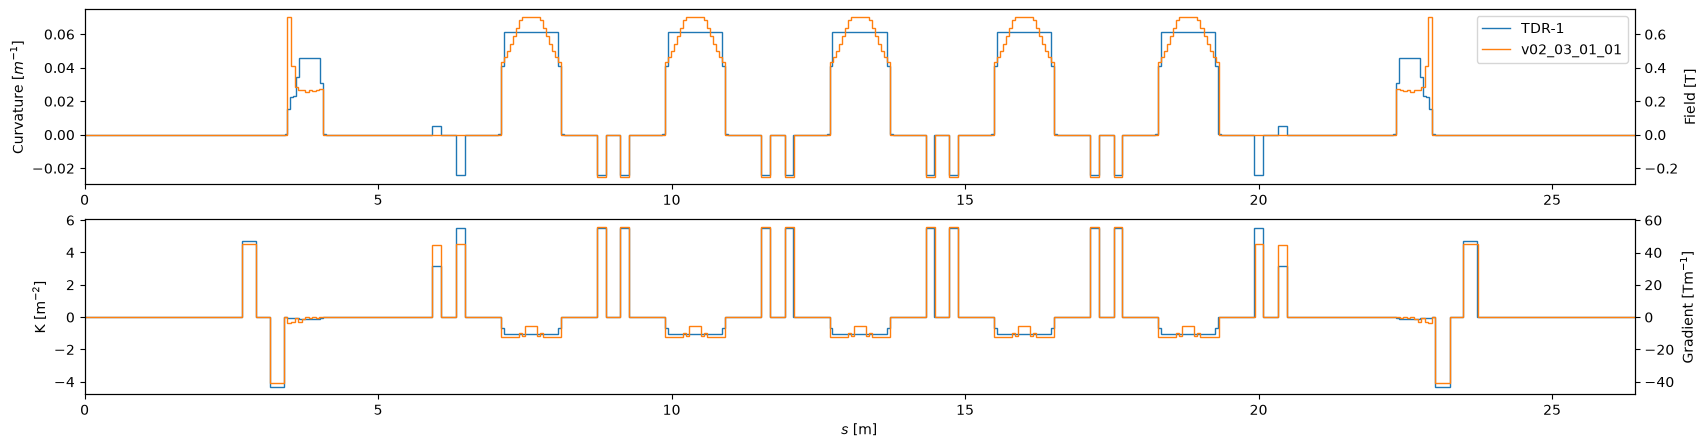

/gpfs/offline1/staff/common/alfpet/git/lattice_design/.venv/lib64/python3.12/site-packages/numpy/_core/fromnumeric.py:3862: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,


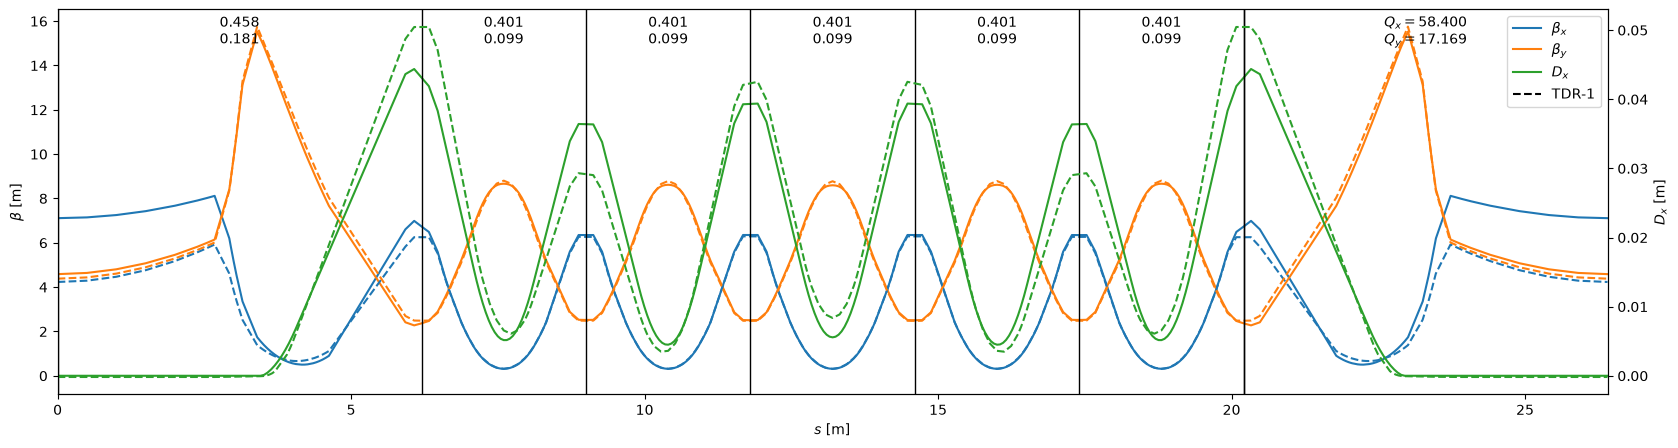

Emittance                  : 51.8 pm.rad
Tunes                      : [58.400, 17.169]
Momentum compaction        : 5.00e-05 d +3.75e-04 d^2 -6.70e-04 d^3
D1 angle                   : 1.125 degrees
Crotch absorber separation : 30.68 mm


In [30]:
fig, axs = plt.subplots(2, 1, figsize=(20, 5))
u.plot.plot_magnet(TDR_1, axs)
u.plot.plot_magnet(ring_opt, axs)

axs[0].legend(['TDR-1', lattice_name])

plt.show()

fig, ax = plt.subplots(1, 1, figsize=(20, 5))
u.plot.linear(ring_opt, ax=ax)

from matplotlib.lines import Line2D
legend_elements = [
    Line2D([], [], color='tab:blue',   ls='-',  label=r'$\beta_x$'),
    Line2D([], [], color='tab:orange', ls='-',  label=r'$\beta_y$'),
    Line2D([], [], color='tab:green',  ls='-',  label=r'$D_x$'),
    Line2D([], [], color='black',      ls='--', label='TDR-1'),
]
ax.legend(handles=legend_elements, loc='best')

plt.show()

u.at.summary(ring_opt)

## Save lattice

In [12]:
try:
    os.mkdir(f'candidates/{lattice_name}')
except FileExistsError:
    pass
    
with open(f'candidates/{lattice_name}/ring.pkl', 'wb') as file:
    pickle.dump(ring_opt, file)

at.save_mat(ring_opt, f'candidates/{lattice_name}/achro.mat')